# Least Squares by Hand

A lab exercise: fit a straight line to noisy data two ways — the closed-form
normal equations worked out with NumPy, and `np.polyfit` as the check. The point
is that the regression everyone imports is four lines of linear algebra.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(7)

plt.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 140,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 9,
})

## The data

Synthetic and deliberately simple: a true line of slope 2.4 and intercept 5,
plus Gaussian noise. Knowing the answer in advance is what makes it a check.


In [2]:
TRUE_SLOPE, TRUE_INTERCEPT, NOISE = 2.4, 5.0, 3.0

x = np.linspace(0, 10, 60)
y = TRUE_INTERCEPT + TRUE_SLOPE * x + rng.normal(0, NOISE, x.size)

print(f"n = {x.size}   x in [{x.min():.1f}, {x.max():.1f}]   y in [{y.min():.1f}, {y.max():.1f}]")

n = 60   x in [0.0, 10.0]   y in [3.5, 32.9]


## The fit

Stack a column of ones onto `x` to get the design matrix, then solve the normal
equations. `lstsq` is used rather than inverting `XᵀX` — same answer, numerically
better behaved when the columns are close to collinear.


In [3]:
X = np.column_stack([np.ones_like(x), x])          # [1, x]
beta, *_ = np.linalg.lstsq(X, y, rcond=None)       # [intercept, slope]
intercept, slope = beta

y_hat = X @ beta
residuals = y - y_hat
r2 = 1 - residuals.var() / y.var()

print(f"slope      {slope:6.3f}   (true {TRUE_SLOPE})")
print(f"intercept  {intercept:6.3f}   (true {TRUE_INTERCEPT})")
print(f"R^2        {r2:6.3f}")
print(f"RMSE       {np.sqrt((residuals ** 2).mean()):6.3f}   (noise sd {NOISE})")

slope       2.607   (true 2.4)
intercept   3.335   (true 5.0)
R^2         0.898
RMSE        2.574   (noise sd 3.0)


Cross-check against `np.polyfit`, which solves the same system:


In [4]:
np.testing.assert_allclose(np.polyfit(x, y, 1), [slope, intercept], rtol=1e-10)
print("normal equations and polyfit agree")

normal equations and polyfit agree


## Reading the result

Two plots. The fit itself, and the residuals — because a good R² says nothing
about whether the line was the right shape. Residuals should look like noise
with no structure left in them.


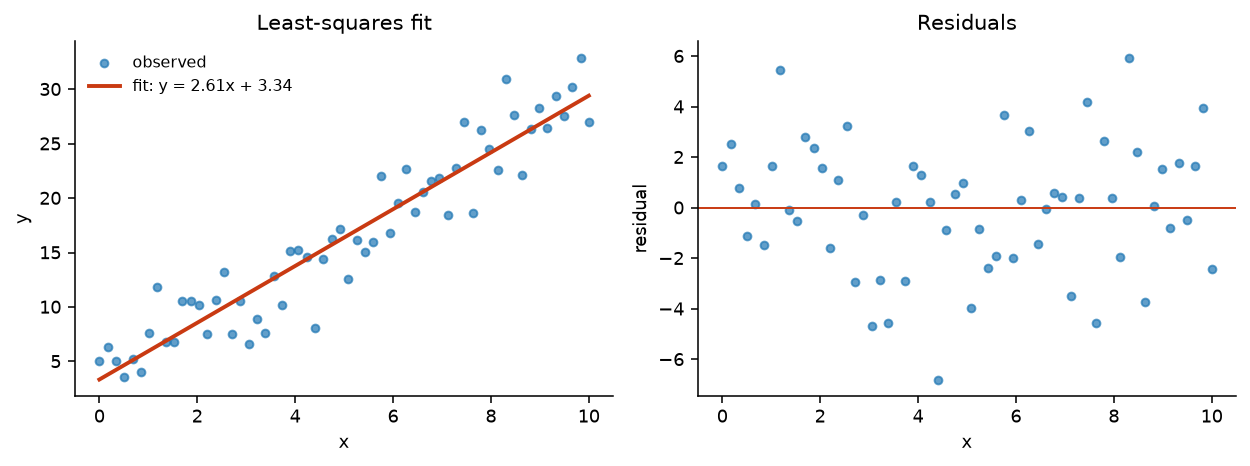

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))

ax1.scatter(x, y, s=16, alpha=0.7, label="observed")
ax1.plot(x, y_hat, lw=2, color="#C93A12", label=f"fit: y = {slope:.2f}x + {intercept:.2f}")
ax1.set(xlabel="x", ylabel="y", title="Least-squares fit")
ax1.legend(frameon=False, fontsize=8)

ax2.axhline(0, lw=1, color="#C93A12")
ax2.scatter(x, residuals, s=16, alpha=0.7)
ax2.set(xlabel="x", ylabel="residual", title="Residuals")

fig.tight_layout()
plt.show()

The residual cloud is flat and centred on zero, so a straight line was the right
model for this data — as it had better be, since a straight line is what generated
it. On real data this plot is where a linear fit usually fails: a smile or a frown
in the residuals means the relationship was curved and the R² was flattering you.
